# UN Comtrade: Mexico and the AI Supply Chain

Pulls UN Comtrade data to see the side of the story U.S. Census cannot show: **where Mexico's inputs come from**, and how the U.S. compares with other suppliers and destinations for the key AI products.

## Why this notebook exists

Census tells us what crosses the U.S. border and how it was routed (domestic export vs re-export). It cannot tell us what Mexico buys from Taiwan, Korea, or Malaysia. Comtrade can, because Mexico is itself a reporter. The two sources answer different questions:

| Question | Source |
|---|---|
| What did the U.S. import from Mexico? | Census (this repo's parquets) |
| Was a U.S. export domestic or a re-export? | Census DF breakout |
| What did Mexico import, and from where? | Comtrade, Mexico as reporter |
| Who supplies the world with these products? | Comtrade, all reporters |

**Important:** Mexico records imports by *country of origin*; the Census re-export data records *routing*. A Taiwanese board that ships through the U.S. to Mexico appears in Mexican statistics as an import from Taiwan and in U.S. statistics as a re-export to Mexico. Neither source alone shows the entrepot pattern.

## API notes

- Free public preview endpoint, **no subscription key**: `https://comtradeapi.un.org/public/v1/preview/C/A/HS`
- Caps at **500 raw records per call** and rate-limits aggressively (HTTP 429), so calls are spaced and cached
- **HS6 only.** Tariff-line detail needs a free registered key and `getTarifflineData()`
- Rows are split by **mode of transport**; `motCode == 0` is the all-modes total. Summing every row double counts, so we filter
- Taiwan reports as partner **490, "Other Asia, nes"**
- Multiple `cmdCode` values per call are allowed; multiple periods are not

Registering a free key at <https://comtradedeveloper.un.org> lifts the record cap and is worth doing if this becomes routine.


In [1]:
import json
import os
import time
import urllib.error
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 40)

REPO = os.path.abspath('..')
CACHE = os.path.join(REPO, 'data-input', 'comtrade')
os.makedirs(CACHE, exist_ok=True)

BASE = 'https://comtradeapi.un.org/public/v1/preview/C/A/HS'
YEARS = [2022, 2023, 2024, 2025]
MEXICO, USA = 484, 842
SLEEP = 6.0          # seconds between calls; the anonymous endpoint 429s below this
RAW_CAP = 500        # preview record cap, used to detect silent truncation

print('cache:', CACHE)

cache: C:\github\ai-trade-index\data-input\comtrade


## 1. Which HS6 codes to pull

Comtrade is HS6, the paper's classification is HS10. We take the high-relevance HS10 codes, roll them to HS6, and keep the largest by 2025 U.S. import value. That keeps the Comtrade work anchored to the paper's definition of AI-related rather than to an ad hoc list.

In [2]:
matlist = pd.read_csv(os.path.join(REPO, 'data-input', 'hs10_classification_final_v3.csv')
                      ).rename(columns={'hs10_code': 'HS10'})

imp = pd.read_parquet(os.path.join(REPO, 'data-input', 'TOTALdata-current.parquet'))
imp = imp.rename(columns={'I_COMMODITY': 'HS10'})
imp['HS10'] = imp['HS10'].astype(str).str.zfill(10)
imp['HS6'] = imp['HS10'].str[:6]
imp['HS2'] = imp['HS10'].str[:2]
imp = imp[~imp['HS2'].isin(['27', '71', '98', '99'])]
imp['time'] = pd.to_datetime(imp['time'], format='%Y-%m')
imp['year'] = imp['time'].dt.year
imp['imports'] = imp['CON_VAL_MO'].astype(float)
imp['HS10i'] = imp['HS10'].astype('int64')
imp = imp.merge(matlist[['HS10', 'relevance', 'primary_category']],
                left_on='HS10i', right_on='HS10', how='left', suffixes=('', '_m'))

high25 = (imp[(imp.relevance == 'High') & (imp.year == 2025)]
          .groupby('HS6')['imports'].sum().sort_values(ascending=False))
total_high25 = high25.sum()

CODES = high25.head(12).index.tolist()
cov = 100 * high25.head(12).sum() / total_high25

lbl = (imp[imp.year == 2025].groupby('HS6')['I_COMMODITY_SDESC'].first())
print(f'Top 12 high-relevance HS6 codes cover {cov:.1f}% of 2025 high-relevance U.S. imports\n')
for c in CODES:
    print(f'  {c}  ${high25[c]/1e9:7.1f}B   {str(lbl.get(c, ""))[:60]}')

CODE_LABEL = {c: str(lbl.get(c, ''))[:40] for c in CODES}

Top 12 high-relevance HS6 codes cover 73.9% of 2025 high-relevance U.S. imports

  847150  $  163.5B   PROC UNT IN HOUS W/ EITHER STOR, IN&OUTPUT,W/ CRT
  851762  $   84.4B   MODEMS OF A KIND USED WITH DATA PRCSG MCH OF 8471
  847330  $   82.5B   PTS ADP MCH, NT INCPTG CRT,PRT CT ASM.,MRY MODULES
  854231  $   28.6B   CONTROLLERS (INCLUDING MICROCONTROLLERS): 8-BIT
  853710  $   19.5B   ELEC APP EQP WTH OTER HUSIN/SUPORT,8421,22,50,8516
  852351  $   17.5B   SOLID-STATE NON-VOLATILE STORAGE DEVICES
  740311  $   16.6B   REFINED COPPER CATHODES AND SECTIONS OF CATHODES
  850760  $   16.5B   LITHUM-ION BATTERES FOR ELEC VEHICLE OF 8703.40-80
  850440  $   16.3B   SPEED DIRVEN CONTROLERS FOR ELECTRIC MOTORS
  847180  $   15.9B   CONTROL OR ADAPTER UNITS FOR ADP MACHINES
  847170  $   13.5B   MAGNETIC DISK DR,DISK DIAM GT 21CM,W/O RD/WRITE
  854442  $    8.3B   ELEC CNDCTRS, 80-1000V, FIT W/MODLR PHONE CONNCTRS


## 2. Download

One call per (reporter, flow, year, code-batch), cached to parquet. Re-running skips anything already on disk, so the cell is resumable if the API rate-limits or the kernel dies. A full cold run is roughly 15 minutes.

Set `FORCE = True` to refresh.

In [3]:
FORCE = False
BATCH = 2            # cmdCodes per call; 2 keeps raw records under the 500 cap


def _batches(seq, n):
    for i in range(0, len(seq), n):
        yield seq[i:i + n]


def fetch(reporter, flow, year, codes, retries=5):
    """One Comtrade call. Returns the all-modes rows (motCode == 0)."""
    url = (f'{BASE}?reporterCode={reporter}&period={year}'
           f'&cmdCode={",".join(codes)}&flowCode={flow}')
    for attempt in range(retries):
        try:
            with urllib.request.urlopen(url, timeout=120) as r:
                raw = json.load(r).get('data', [])
            if len(raw) >= RAW_CAP:
                print(f'    WARNING: {len(raw)} records hit the {RAW_CAP} cap '
                      f'({reporter}/{flow}/{year}/{codes}) | reduce BATCH')
            return [x for x in raw if x.get('motCode') == 0]
        except urllib.error.HTTPError as e:
            if e.code == 429 and attempt < retries - 1:
                time.sleep(15 * (attempt + 1))
                continue
            if attempt == retries - 1:
                print(f'    ERROR {reporter}/{flow}/{year}/{codes}: {e}')
                return []
        except Exception as e:
            if attempt == retries - 1:
                print(f'    ERROR {reporter}/{flow}/{year}/{codes}: {e}')
                return []
            time.sleep(10)
    return []


def pull(reporter, flow, year, codes=None):
    """Cached pull of one (reporter, flow, year) across all codes."""
    codes = codes or CODES
    path = os.path.join(CACHE, f'comtrade_{reporter}_{flow}_{year}.parquet')
    if os.path.exists(path) and not FORCE:
        return pd.read_parquet(path)
    rows = []
    for b in _batches(codes, BATCH):
        rows += fetch(reporter, flow, year, b)
        time.sleep(SLEEP)
    if not rows:
        print(f'  no data: {reporter}/{flow}/{year}')
        return pd.DataFrame()
    df = pd.DataFrame(rows)[['reporterCode', 'partnerCode', 'cmdCode', 'flowCode',
                             'period', 'primaryValue', 'netWgt', 'qty']]
    df.to_parquet(path, index=False)
    print(f'  saved {os.path.basename(path)}  ({len(df)} rows)')
    return df


jobs = [(r, f, y) for r in (MEXICO, USA) for f in ('M', 'X') for y in YEARS]
frames = []
for i, (r, f, y) in enumerate(jobs, 1):
    print(f'[{i}/{len(jobs)}] reporter={r} flow={f} {y}')
    frames.append(pull(r, f, y))

ct = pd.concat([d for d in frames if len(d)], ignore_index=True)
print(f'\ntotal rows: {len(ct):,}')

[1/16] reporter=484 flow=M 2022


  saved comtrade_484_M_2022.parquet  (499 rows)
[2/16] reporter=484 flow=M 2023


  saved comtrade_484_M_2023.parquet  (500 rows)
[3/16] reporter=484 flow=M 2024


  saved comtrade_484_M_2024.parquet  (492 rows)
[4/16] reporter=484 flow=M 2025


  saved comtrade_484_M_2025.parquet  (486 rows)
[5/16] reporter=484 flow=X 2022


  saved comtrade_484_X_2022.parquet  (496 rows)
[6/16] reporter=484 flow=X 2023


... (7 outputs left out)

  saved comtrade_842_X_2022.parquet  (1972 rows)
[14/16] reporter=842 flow=X 2023


  saved comtrade_842_X_2023.parquet  (1975 rows)
[15/16] reporter=842 flow=X 2024


  saved comtrade_842_X_2024.parquet  (1955 rows)
[16/16] reporter=842 flow=X 2025


  saved comtrade_842_X_2025.parquet  (1956 rows)

total rows: 16,239


In [4]:
# Partner names (cached reference file)
ref_path = os.path.join(CACHE, 'partnerAreas.json')
if not os.path.exists(ref_path):
    with urllib.request.urlopen('https://comtradeapi.un.org/files/v1/app/reference/partnerAreas.json',
                                timeout=60) as r:
        ref = json.load(r)
    with open(ref_path, 'w', encoding='utf-8') as f:
        json.dump(ref, f)
else:
    ref = json.load(open(ref_path, encoding='utf-8'))

rows = ref['results'] if isinstance(ref, dict) and 'results' in ref else ref
PARTNER = {int(x['id']): x['text'] for x in rows if str(x['id']).isdigit()}
PARTNER[490] = 'Taiwan (Other Asia, nes)'

ct['partner'] = ct['partnerCode'].map(PARTNER).fillna(ct['partnerCode'].astype(str))
ct['reporter'] = ct['reporterCode'].map({MEXICO: 'Mexico', USA: 'USA'})
ct['value'] = ct['primaryValue'].astype(float)
ct['year'] = ct['period'].astype(int)
print(ct.groupby(['reporter', 'flowCode'])['value'].sum().div(1e9).round(1).to_string())

reporter  flowCode
Mexico    M            624.3
          X            584.1
USA       M           2594.2
          X           1031.7


## 3. Does this line up with the Census data?

Three checks, in increasing order of how much they should worry us.

1. **Comtrade USA reporter vs this repo's Census parquet.** Comtrade sources U.S. data from Census, so these should agree closely. Differences come from consumption vs general imports and from revision vintages. Anything beyond a few percent means we are misreading the API.
2. **Mexico's reported exports to the U.S. vs the U.S. reported imports from Mexico.** Classic mirror asymmetry. Expect a gap.
3. **Coverage.** Whether the HS6 aggregates capture the HS10 codes the paper cares about.

In [5]:
# Census side, aggregated to HS6
census_us = (imp[imp.HS6.isin(CODES)]
             .groupby(['HS6', 'year'])['imports'].sum().div(1e9).rename('census_us_imports'))

# Comtrade, USA reporter, imports from World
ct_us = (ct[(ct.reporter == 'USA') & (ct.flowCode == 'M') & (ct.partnerCode == 0)]
         .groupby(['cmdCode', 'year'])['value'].sum().div(1e9).rename('comtrade_us_imports'))
ct_us.index.names = ['HS6', 'year']

chk1 = pd.concat([census_us, ct_us], axis=1).dropna()
chk1['ratio'] = chk1.comtrade_us_imports / chk1.census_us_imports
print('CHECK 1 | Comtrade USA-reporter imports vs Census parquet, $B')
print(chk1.loc[chk1.index.get_level_values('year') >= 2023].round(2).to_string())
print(f'\nmedian ratio: {chk1.ratio.median():.3f}   '
      f'(1.00 = identical; small deviations are consumption vs general imports)')

CHECK 1 | Comtrade USA-reporter imports vs Census parquet, $B
             census_us_imports  comtrade_us_imports  ratio
HS6    year                                               
740311 2023               6.65                 6.67   1.00
       2024               8.41                 8.54   1.02
       2025              16.64                16.69   1.00
847150 2023              36.93                37.06   1.00
       2024              61.63                61.93   1.00
       2025             163.55               164.57   1.01
847170 2023               7.44                 7.54   1.01
       2024               9.16                 9.69   1.06
       2025              13.46                13.99   1.04
847180 2023               4.83                 4.92   1.02
       2024              11.22                11.39   1.01
       2025              15.87                16.77   1.06
847330 2023              29.33                31.91   1.09
       2024              50.88                54.30  

In [6]:
# Census: U.S. imports from Mexico, by HS6
mx_census = pd.read_parquet(os.path.join(REPO, 'data-input', 'ALL-data-current.parquet'),
                            filters=[('CTY_NAME', '==', 'MEXICO')])
mx_census = mx_census.rename(columns={'I_COMMODITY': 'HS10'})
mx_census['HS10'] = mx_census['HS10'].astype(str).str.zfill(10)
mx_census['HS6'] = mx_census['HS10'].str[:6]
mx_census['year'] = pd.to_datetime(mx_census['time'], format='%Y-%m').dt.year
mx_census['imports'] = mx_census['CON_VAL_MO'].astype(float)
census_from_mx = (mx_census[mx_census.HS6.isin(CODES)]
                  .groupby(['HS6', 'year'])['imports'].sum().div(1e9)
                  .rename('census_us_imports_from_mx'))

# Comtrade: Mexico reported exports to the USA
mx_to_us = (ct[(ct.reporter == 'Mexico') & (ct.flowCode == 'X') & (ct.partnerCode == USA)]
            .groupby(['cmdCode', 'year'])['value'].sum().div(1e9).rename('comtrade_mx_exports_to_us'))
mx_to_us.index.names = ['HS6', 'year']

chk2 = pd.concat([census_from_mx, mx_to_us], axis=1).dropna()
chk2['mirror_ratio'] = chk2.census_us_imports_from_mx / chk2.comtrade_mx_exports_to_us
print('CHECK 2 | mirror: U.S.-reported imports from Mexico vs Mexico-reported exports to U.S., $B')
print(chk2.loc[chk2.index.get_level_values('year') >= 2023].round(2).to_string())
print(f'\nmedian mirror ratio: {chk2.mirror_ratio.median():.2f}  '
      '(>1 means the U.S. reports more than Mexico does)')

CHECK 2 | mirror: U.S.-reported imports from Mexico vs Mexico-reported exports to U.S., $B
             census_us_imports_from_mx  comtrade_mx_exports_to_us  mirror_ratio
HS6    year                                                                    
740311 2023                       0.12                       0.04          2.83
       2025                       0.34                       0.26          1.33
847150 2023                      25.00                      18.73          1.33
       2024                      41.60                      23.46          1.77
       2025                      80.56                      64.80          1.24
847170 2023                       1.60                       1.33          1.20
       2024                       2.33                       1.29          1.80
       2025                       3.61                       1.66          2.17
847180 2023                       0.20                       1.51          0.13
       2024                  

In [7]:
# CHECK 3 | how much of the paper's high-relevance trade do these 12 HS6 codes carry?
for yr in [2023, 2025]:
    tot_high = imp[(imp.relevance == 'High') & (imp.year == yr)]['imports'].sum()
    in_codes = imp[(imp.relevance == 'High') & (imp.year == yr) & (imp.HS6.isin(CODES))]['imports'].sum()
    # how much non-high trade rides along inside the same HS6 buckets
    contam = imp[(imp.relevance != 'High') & (imp.year == yr) & (imp.HS6.isin(CODES))]['imports'].sum()
    print(f'{yr}: HS6 set covers {100*in_codes/tot_high:5.1f}% of high-relevance imports; '
          f'non-high trade inside the same HS6 buckets = ${contam/1e9:.1f}B '
          f'({100*contam/(in_codes+contam):.1f}% of the bucket)')

2023: HS6 set covers  57.4% of high-relevance imports; non-high trade inside the same HS6 buckets = $4.8B (2.2% of the bucket)


2025: HS6 set covers  73.9% of high-relevance imports; non-high trade inside the same HS6 buckets = $3.8B (0.8% of the bucket)


## 4. Where Mexico's inputs come from

This is the question Census cannot answer. Note again that these are **countries of origin**, so goods routed through the U.S. as re-exports appear under their Asian origin, not under the USA.

In [8]:
mx_imp = ct[(ct.reporter == 'Mexico') & (ct.flowCode == 'M')]

world = (mx_imp[mx_imp.partnerCode == 0]
         .pivot_table(index='cmdCode', columns='year', values='value', aggfunc='sum').div(1e9))
world['label'] = [CODE_LABEL.get(c, '') for c in world.index]
print("Mexico's imports from the world, $B")
print(world.round(2).to_string())

Mexico's imports from the world, $B
year      2022   2023   2024   2025                                     label
cmdCode                                                                      
740311    0.19   0.97   1.52   1.28  REFINED COPPER CATHODES AND SECTIONS OF 
847150    1.03   1.17   1.25  15.87  PROC UNT IN HOUS W/ EITHER STOR, IN&OUTP
847170    6.17   4.38   6.44   8.84  MAGNETIC DISK DR,DISK DIAM GT 21CM,W/O R
847180    1.30   1.26   1.96   3.87  CONTROL OR ADAPTER UNITS FOR ADP MACHINE
847330   13.83  10.85  15.96  34.65  PTS ADP MCH, NT INCPTG CRT,PRT CT ASM.,M
850440    3.44   3.73   4.06   4.70  SPEED DIRVEN CONTROLERS FOR ELECTRIC MOT
850760    2.71   3.90   5.66   4.28  LITHUM-ION BATTERES FOR ELEC VEHICLE OF 
851762    8.17   7.91   8.22  11.74  MODEMS OF A KIND USED WITH DATA PRCSG MC
852351    3.53   2.59   4.42   4.79  SOLID-STATE NON-VOLATILE STORAGE DEVICES
853710    2.54   2.76   3.12   3.15  ELEC APP EQP WTH OTER HUSIN/SUPORT,8421,
854231   17.62  16.07  18.71

In [9]:
def origin_table(code, year=2025, n=6):
    d = mx_imp[(mx_imp.cmdCode == code) & (mx_imp.year == year)]
    w = d.loc[d.partnerCode == 0, 'value'].sum()
    t = (d[d.partnerCode != 0].groupby('partner')['value'].sum().sort_values(ascending=False).head(n))
    out = (t / 1e9).to_frame('value_bn')
    out['share_%'] = 100 * t / w
    return out

for c in CODES[:6]:
    print(f'\n=== {c}  {CODE_LABEL.get(c, "")} | Mexico imports 2025 ===')
    print(origin_table(c).round(2).to_string())


=== 847150  PROC UNT IN HOUS W/ EITHER STOR, IN&OUTP | Mexico imports 2025 ===
                          value_bn  share_%
partner                                    
Taiwan (Other Asia, nes)     13.12    82.67
USA                           2.07    13.07
China                         0.39     2.47
Viet Nam                      0.12     0.74
Netherlands                   0.06     0.39
Malaysia                      0.03     0.20

=== 851762  MODEMS OF A KIND USED WITH DATA PRCSG MC | Mexico imports 2025 ===
                          value_bn  share_%
partner                                    
China                         2.51    21.39
Viet Nam                      2.38    20.27
USA                           1.78    15.16
Thailand                      1.55    13.23
Taiwan (Other Asia, nes)      0.97     8.29
Malaysia                      0.85     7.21

=== 847330  PTS ADP MCH, NT INCPTG CRT,PRT CT ASM.,M | Mexico imports 2025 ===
                          value_bn  share_%
partner     

In [10]:
# Origin shares over time for the big component codes
FOCUS = [c for c in ['847330', '854231', '852351', '847150'] if c in CODES]
for c in FOCUS:
    d = mx_imp[mx_imp.cmdCode == c]
    w = d[d.partnerCode == 0].groupby('year')['value'].sum()
    p = (d[d.partnerCode != 0].pivot_table(index='partner', columns='year',
                                           values='value', aggfunc='sum'))
    p = p.div(w, axis=1) * 100
    p = p.loc[p[max(YEARS)].sort_values(ascending=False).head(6).index]
    print(f'\n=== {c} {CODE_LABEL.get(c, "")} | Mexico import shares by origin (%) ===')
    print(p.round(1).to_string())
    print('   world total, $B: ' + ', '.join(f'{y}: {w.get(y, np.nan)/1e9:.1f}' for y in YEARS))


=== 847330 PTS ADP MCH, NT INCPTG CRT,PRT CT ASM.,M | Mexico import shares by origin (%) ===
year                      2022  2023  2024  2025
partner                                         
Taiwan (Other Asia, nes)  15.2  23.1  26.3  47.1
China                     43.0  41.9  33.0  18.0
Viet Nam                   6.8   4.7   9.5  12.4
Rep. of Korea             21.4  16.6  15.8  10.4
Malaysia                   4.4   3.8   6.1   6.0
USA                        4.6   5.2   4.5   2.7
   world total, $B: 2022: 13.8, 2023: 10.8, 2024: 16.0, 2025: 34.6

=== 854231 CONTROLLERS (INCLUDING MICROCONTROLLERS) | Mexico import shares by origin (%) ===
year                      2022  2023  2024  2025
partner                                         
Malaysia                  41.1  31.0  28.2  30.4
Taiwan (Other Asia, nes)   9.6  12.6  17.9  19.8
China                     19.5  14.9  11.4  12.1
Viet Nam                   9.6  16.2  12.4   9.4
Costa Rica                 4.8   5.6   8.2   8.2
Rep. of Ko

## 5. Where Mexico's output goes

In [11]:
mx_exp = ct[(ct.reporter == 'Mexico') & (ct.flowCode == 'X')]

w = (mx_exp[mx_exp.partnerCode == 0]
     .pivot_table(index='cmdCode', columns='year', values='value', aggfunc='sum').div(1e9))
us = (mx_exp[mx_exp.partnerCode == USA]
      .pivot_table(index='cmdCode', columns='year', values='value', aggfunc='sum').div(1e9))
share = (100 * us / w)
out = pd.concat({'world_bn': w[max(YEARS)], 'to_usa_bn': us[max(YEARS)],
                 'usa_share_%': share[max(YEARS)]}, axis=1)
out['label'] = [CODE_LABEL.get(c, '') for c in out.index]
print(f"Mexico's exports, {max(YEARS)}")
print(out.round(1).to_string())
print('\nShare of Mexican exports going to the U.S. (%), by year')
print(share.round(1).to_string())

Mexico's exports, 2025
         world_bn  to_usa_bn  usa_share_%                                     label
cmdCode                                                                            
740311        0.3        0.3        100.0  REFINED COPPER CATHODES AND SECTIONS OF 
847150       69.4       64.8         93.3  PROC UNT IN HOUS W/ EITHER STOR, IN&OUTP
847170        2.4        1.7         70.7  MAGNETIC DISK DR,DISK DIAM GT 21CM,W/O R
847180        3.2        2.9         91.9  CONTROL OR ADAPTER UNITS FOR ADP MACHINE
847330        9.1        8.2         90.2  PTS ADP MCH, NT INCPTG CRT,PRT CT ASM.,M
850440        2.5        2.3         92.6  SPEED DIRVEN CONTROLERS FOR ELECTRIC MOT
850760        1.6        1.5         97.5  LITHUM-ION BATTERES FOR ELEC VEHICLE OF 
851762       15.5       12.3         79.7  MODEMS OF A KIND USED WITH DATA PRCSG MC
852351        0.3        0.2         63.2  SOLID-STATE NON-VOLATILE STORAGE DEVICES
853710        8.7        8.0         91.5  ELEC APP E

## 6. The world picture

Who supplies these products globally, and how has that shifted since 2022? Uses the U.S. and Mexico reporters we already pulled plus world-level partner rows.

In [12]:
# U.S. imports by source for the key codes, Comtrade view (cross-check on the paper's country story)
us_imp = ct[(ct.reporter == 'USA') & (ct.flowCode == 'M')]
for c in FOCUS:
    d = us_imp[us_imp.cmdCode == c]
    w = d[d.partnerCode == 0].groupby('year')['value'].sum()
    p = d[d.partnerCode != 0].pivot_table(index='partner', columns='year', values='value', aggfunc='sum')
    p = (p.div(w, axis=1) * 100)
    p = p.loc[p[max(YEARS)].sort_values(ascending=False).head(6).index]
    print(f'\n=== {c} {CODE_LABEL.get(c, "")} | U.S. import shares by source (%) ===')
    print(p.round(1).to_string())


=== 847330 PTS ADP MCH, NT INCPTG CRT,PRT CT ASM.,M | U.S. import shares by source (%) ===
year                      2022  2023  2024  2025
partner                                         
Taiwan (Other Asia, nes)  29.5  43.4  46.2  52.2
Viet Nam                  10.7   7.3  11.7  15.3
Rep. of Korea             22.6  12.1  12.9  10.7
China                     20.9  20.3  12.1   6.5
Malaysia                   3.9   4.3   7.0   6.0
Mexico                     4.0   4.3   3.2   4.1

=== 854231 CONTROLLERS (INCLUDING MICROCONTROLLERS) | U.S. import shares by source (%) ===
year                      2022  2023  2024  2025
partner                                         
Taiwan (Other Asia, nes)  10.9  13.7  28.4  31.3
Malaysia                  43.9  32.8  27.1  28.4
Israel                     4.6   9.8  14.5  13.3
Costa Rica                 3.3   5.4   4.3   7.2
Ireland                    8.5   8.3   6.8   5.5
Viet Nam                   9.2   8.2   4.5   3.0

=== 852351 SOLID-STATE NON-VOLA

In [13]:
# Mexico's position: inputs in vs output out, for the compute chain
INPUTS = [c for c in ['847330', '854231', '852351'] if c in CODES]
OUTPUT = '847150'

inp = (mx_imp[(mx_imp.cmdCode.isin(INPUTS)) & (mx_imp.partnerCode == 0)]
       .groupby('year')['value'].sum().div(1e9))
outp = (mx_exp[(mx_exp.cmdCode == OUTPUT) & (mx_exp.partnerCode == 0)]
        .groupby('year')['value'].sum().div(1e9))
unit_imp = (mx_imp[(mx_imp.cmdCode == OUTPUT) & (mx_imp.partnerCode == 0)]
            .groupby('year')['value'].sum().div(1e9))

tbl = pd.DataFrame({'component_imports': inp, 'unit_imports': unit_imp, 'unit_exports': outp})
tbl['inputs_total'] = tbl.component_imports + tbl.unit_imports
tbl['exports_over_inputs'] = tbl.unit_exports / tbl.inputs_total
print('Mexico compute chain, $B (Comtrade, HS6)')
print(tbl.round(2).to_string())

Mexico compute chain, $B (Comtrade, HS6)
      component_imports  unit_imports  unit_exports  inputs_total  exports_over_inputs
year                                                                                  
2022              34.98          1.03         28.29         36.01                 0.79
2023              29.51          1.17         19.91         30.69                 0.65
2024              39.09          1.25         24.91         40.34                 0.62
2025              60.07         15.87         69.43         75.95                 0.91


## 7. Figures

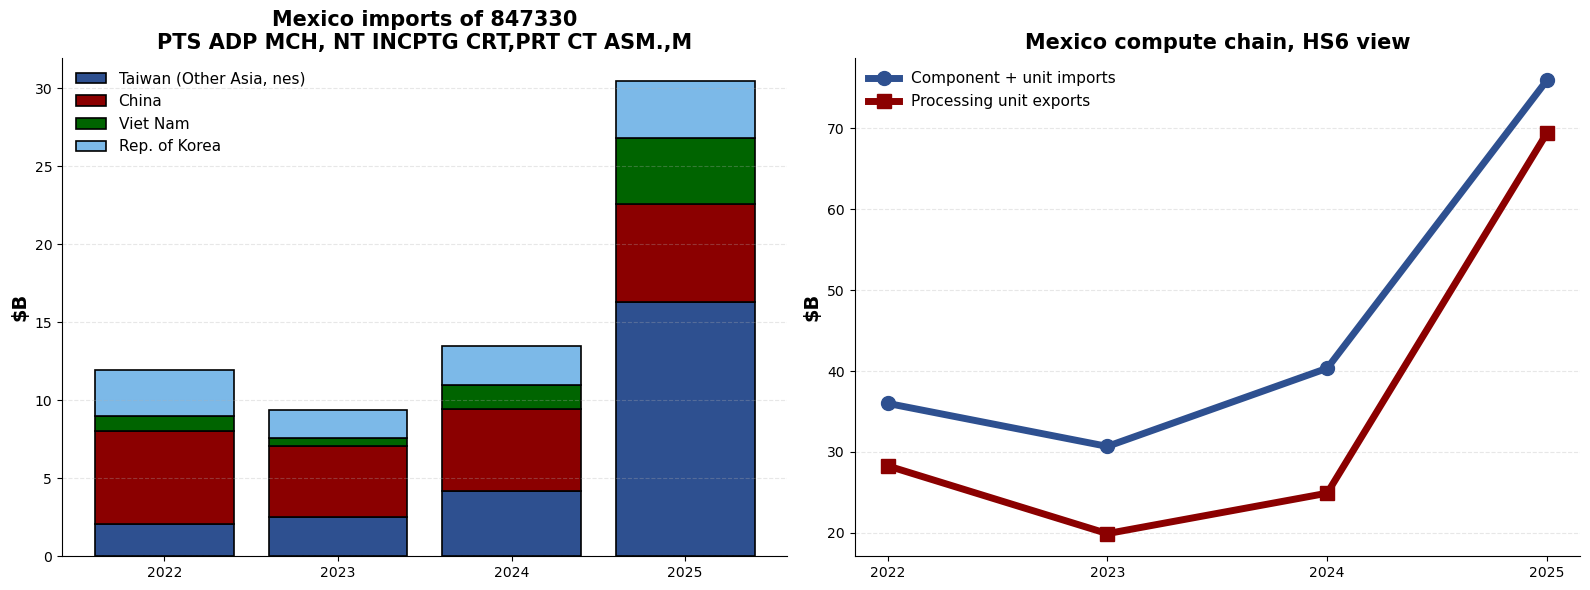

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ax = axes[0]
c = '847330'
d = mx_imp[mx_imp.cmdCode == c]
w = d[d.partnerCode == 0].groupby('year')['value'].sum() / 1e9
p = d[d.partnerCode != 0].pivot_table(index='partner', columns='year', values='value', aggfunc='sum') / 1e9
top = p[max(YEARS)].sort_values(ascending=False).head(4).index
bottom = np.zeros(len(YEARS))
colors = ['#2E5090', '#8B0000', 'darkgreen', '#7CB9E8']
for i, k in enumerate(top):
    v = p.loc[k].reindex(YEARS).fillna(0).values
    ax.bar([str(y) for y in YEARS], v, bottom=bottom, label=k,
           color=colors[i % len(colors)], edgecolor='black', linewidth=1.2)
    bottom += v
ax.set_title(f'Mexico imports of {c}\n{CODE_LABEL.get(c, "")}', fontsize=15, fontweight='bold')
ax.set_ylabel('$B', fontsize=14, fontweight='bold')
ax.legend(fontsize=11, frameon=False)
for s in ('right', 'top'):
    ax.spines[s].set_visible(False)
ax.grid(axis='y', alpha=0.3, linestyle='--')

ax = axes[1]
ax.plot(tbl.index, tbl.inputs_total, color='#2E5090', linewidth=5, marker='o',
        markersize=10, label='Component + unit imports')
ax.plot(tbl.index, tbl.unit_exports, color='#8B0000', linewidth=5, marker='s',
        markersize=10, label='Processing unit exports')
ax.set_title('Mexico compute chain, HS6 view', fontsize=15, fontweight='bold')
ax.set_ylabel('$B', fontsize=14, fontweight='bold')
ax.set_xticks(list(tbl.index))
ax.legend(fontsize=11, frameon=False)
for s in ('right', 'top'):
    ax.spines[s].set_visible(False)
ax.grid(axis='y', alpha=0.3, linestyle='--')

plt.tight_layout()
plt.savefig(os.path.join(REPO, 'figures-mexico', 'comtrade-mexico-inputs.png'), bbox_inches='tight')
plt.show()

## 8. What is worth putting in the report

Fill this in after reading the output above. Candidates:

- Origin vs routing: the same goods appear as Taiwanese in Mexican statistics and as U.S. re-exports in Census statistics
- Mexico's shift in input origins since 2022
- The 2025 jump in Mexican imports of assembled units, and what it means for the round-trip reading
- Mirror gap between U.S. and Mexican reporting, and which to trust for what